## Project Overview & Business Objective

The goal of this project is to help a medium-sized football club with a limited budget identify suitable young players for recruitment.

The club aims to find promising players who combine high future potential with sufficient current performance while remaining within its financial constraints.

Using player data, the analysis evaluates player ratings, potential, market value, and wages to identify affordable recruitment opportunities.

The project also examines tactical suitability by comparing strikers based on attributes relevant to a counter-attacking playing style.

The final objective is to provide the sporting director with data-driven insights and recruitment recommendations that balance player quality, future potential, and estimated financial cost.

## Dataset Overview

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("fifa_players.csv")
df.head(5)

,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,6/24/1987,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,2/14/1992,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,3/15/1993,25,190.50,83.9,"CM,CAM",France,88,91,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,6/4/1991,27,162.56,59.0,"LW,ST",Italy,88,88,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,6/20/1991,27,187.96,88.9,CB,Senegal,88,91,...,15,87,88,24,49,33,80,91,88,87


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17954 entries, 0 to 17953
Data columns (total 51 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   name                           17954 non-null  object 
 1   full_name                      17954 non-null  object 
 2   birth_date                     17954 non-null  object 
 3   age                            17954 non-null  int64  
 4   height_cm                      17954 non-null  float64
 5   weight_kgs                     17954 non-null  float64
 6   positions                      17954 non-null  object 
 7   nationality                    17954 non-null  object 
 8   overall_rating                 17954 non-null  int64  
 9   potential                      17954 non-null  int64  
 10  value_euro                     17699 non-null  float64
 11  wage_euro                      17708 non-null  float64
 12  preferred_foot                 17954 non-null 

In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.describe()

,age,height_cm,weight_kgs,overall_rating,potential,value_euro,wage_euro,international_reputation(1-5),weak_foot(1-5),skill_moves(1-5),...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
count,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,1.769900e+04,17708.000000,17954.000000,17954.000000,17954.000000,...,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000,17954.000000
mean,25.565445,174.946921,75.301047,66.240169,71.430935,2.479280e+06,9902.134628,1.111674,2.945695,2.361034,...,46.852456,55.816531,46.657959,49.857302,53.406260,48.357302,58.680183,47.162861,47.733040,45.705915
std,4.705708,14.029449,7.083684,6.963730,6.131339,5.687014e+06,21995.593750,0.392168,0.663691,0.763223,...,19.429337,17.394047,20.754649,19.694311,14.156038,15.810844,11.625541,20.037346,21.674973,21.285812
min,17.000000,152.400000,49.900000,47.000000,48.000000,1.000000e+04,1000.000000,1.000000,1.000000,1.000000,...,3.000000,11.000000,3.000000,2.000000,10.000000,5.000000,12.000000,3.000000,2.000000,3.000000
25%,22.000000,154.940000,69.900000,62.000000,67.000000,3.250000e+05,1000.000000,1.000000,3.000000,2.000000,...,32.000000,44.000000,26.000000,38.000000,44.000000,38.000000,51.000000,30.000000,27.000000,24.000000
50%,25.000000,175.260000,74.800000,66.000000,71.000000,7.000000e+05,3000.000000,1.000000,3.000000,2.000000,...,51.000000,59.000000,52.000000,55.000000,55.000000,49.000000,60.000000,52.500000,55.000000,52.000000
75%,29.000000,185.420000,79.800000,71.000000,75.000000,2.100000e+06,9000.000000,1.000000,3.000000,3.000000,...,62.000000,69.000000,64.000000,64.000000,64.000000,60.000000,67.000000,64.000000,66.000000,64.000000
max,46.000000,205.740000,110.200000,94.000000,95.000000,1.105000e+08,565000.000000,5.000000,5.000000,5.000000,...,94.000000,95.000000,92.000000,95.000000,94.000000,92.000000,96.000000,94.000000,93.000000,90.000000


In [6]:
missing_values = df.isna().sum()
missing_values[missing_values > 0]

value_euro                  255
wage_euro                   246
release_clause_euro        1837
national_team             17097
national_rating           17097
national_team_position    17097
national_jersey_number    17097
dtype: int64

## Data Cleaning & Quality

In [7]:
filtering = df[(df['age'] <= 23) & (df['potential'] >= 80)]

In [8]:
len(filtering) 

1069

In [9]:
missing_value_players = filtering['value_euro'].isna().sum()
print(missing_value_players)

4


In [10]:
missing_value_avg = filtering.loc[filtering['value_euro'].isna(), 'potential'].mean()

recorded_value_avg = filtering.loc[filtering['value_euro'].notna(), 'potential'].mean()

print("Average potential (missing value):", round(missing_value_avg, 2))
print("Average potential (recorded value):", round(recorded_value_avg, 2))

Average potential (missing value): 82.75
Average potential (recorded value): 82.78


In [11]:
missing_value_age_17_23 = df[(df['age'].between(17, 23)) &(df['value_euro'].isna())]
print(len(missing_value_age_17_23))

51


In [12]:
missing_value_age_24_29 = df[(df['age'].between(24, 29)) & (df['value_euro'].isna())]
print(len(missing_value_age_24_29))

121


In [13]:
missing_value_age_30_plus = df[(df['age'] >= 30) & (df['value_euro'].isna())]
print(len(missing_value_age_30_plus))

83


### Data Quality — Key Findings & Decisions

**Dataset Overview**
- Total players: 17,954
- Players with missing market values: 255 (1.42%).
- Players with recorded market values: 17,699.

**Missing Market Values by Age Group**
- Ages 17–23: 51 players (0.75% of the age group).
- Ages 24–29: 121 players (1.66%).
- Ages 30+: 83 players (2.13%).

The 24–29 age group has the highest number of missing market values, while players aged 30+ have the highest missing-value rate.

**Young Talent Analysis**

Among players aged 23 or younger with a potential rating of at least 80:
- Total players: 1,069.
- Players with missing market values: 4 (0.37%).
- The average potential rating is 82.75 for players with missing values and 82.78 for players with recorded values.

The missing-value group contains only four players, so broader conclusions about differences between the groups are not justified.

**Data Quality Decisions**
1. Retain all players in the original dataset.
2. Exclude missing market values only from analyses that require market value.
3. Do not replace missing market values with zero.
4. Players with missing market values or wages are retained in the original dataset but excluded from the financial recruitment analysis because their estimated costs cannot be calculated reliably. They may still be considered for scouting.

**Business Implication**

Missing market values have a limited impact on the young high-potential player segment. Players without recorded values can still be considered for scouting, with their estimated values potentially assessed through comparisons with similar players.

**Limitation:** FIFA player ratings and market values are game-based data and should not be treated as verified real-world scouting assessments.

In [14]:
players_with_value = df[df['value_euro'].notna()].copy()

In [15]:
players_with_value.head()

,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,6/24/1987,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,2/14/1992,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,3/15/1993,25,190.50,83.9,"CM,CAM",France,88,91,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,6/4/1991,27,162.56,59.0,"LW,ST",Italy,88,88,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,6/20/1991,27,187.96,88.9,CB,Senegal,88,91,...,15,87,88,24,49,33,80,91,88,87


In [16]:
len(players_with_value)

17699

In [17]:
players_with_value_and_salary = players_with_value[players_with_value['wage_euro'].notna()].copy()

In [18]:
players_with_value_and_salary.head()

,name,full_name,birth_date,age,height_cm,weight_kgs,positions,nationality,overall_rating,potential,...,long_shots,aggression,interceptions,positioning,vision,penalties,composure,marking,standing_tackle,sliding_tackle
0,L. Messi,Lionel Andrés Messi Cuccittini,6/24/1987,31,170.18,72.1,"CF,RW,ST",Argentina,94,94,...,94,48,22,94,94,75,96,33,28,26
1,C. Eriksen,Christian Dannemann Eriksen,2/14/1992,27,154.94,76.2,"CAM,RM,CM",Denmark,88,89,...,89,46,56,84,91,67,88,59,57,22
2,P. Pogba,Paul Pogba,3/15/1993,25,190.50,83.9,"CM,CAM",France,88,91,...,82,78,64,82,88,82,87,63,67,67
3,L. Insigne,Lorenzo Insigne,6/4/1991,27,162.56,59.0,"LW,ST",Italy,88,88,...,84,34,26,83,87,61,83,51,24,22
4,K. Koulibaly,Kalidou Koulibaly,6/20/1991,27,187.96,88.9,CB,Senegal,88,91,...,15,87,88,24,49,33,80,91,88,87


In [19]:
players_with_value_and_salary[['value_euro', 'wage_euro']].isna().sum()

value_euro    0
wage_euro     0
dtype: int64

## EDA & Recruitment Analysis

### Player Market Value Segmentation

In [20]:
import numpy as np

In [21]:
column_index = players_with_value.columns.get_loc('potential') + 1
players_with_value['price_group'] = pd.cut(players_with_value['value_euro'],bins=[0, 3_000_000, 10_000_000, np.inf],labels=['low', 'medium', 'high'])

In [22]:
players_with_value['price_group'].value_counts()

price_group
low       14221
medium     2603
high        875
Name: count, dtype: int64

In [23]:
young_talent = players_with_value[(players_with_value['age'] <= 23).copy()]

In [24]:
young_talent['price_group'].value_counts()

price_group
low       5998
medium     530
high       217
Name: count, dtype: int64

In [25]:
result = young_talent.groupby('price_group', observed=True).agg({
    'name' : 'count',
    'overall_rating' : 'mean',
    'potential' : 'mean'
})
result

,name,overall_rating,potential
price_group,,,
low,5998,60.579527,72.083361
medium,530,72.726415,81.486792
high,217,78.281106,85.824885


### Business Insight — Market Value vs Player Quality

Higher market-value groups show higher average overall ratings and potential among players aged 23 or younger.

However, the low-value segment contains 5,998 young players, making it a substantial recruitment pool for a budget-constrained club.

Rather than targeting expensive players by default, the club should apply additional performance, potential, and salary filters to identify promising candidates within its financial limits.

## Scouting Value Analysis

### Recruitment Shortlist

### Recruitment Criteria — Business Assumptions

The recruitment shortlist is based on a hypothetical medium-sized football club with a limited budget.

- **Age ≤ 23:** Focus on young players with potential for future development.
- **Potential ≥ 80:** Identify players with high projected development potential in FIFA.
- **Market value ≤ €3M:** Set an assumed affordability threshold for player valuation.
- **Weekly wage ≤ €10,000:** Limit estimated salary commitments.
- **Overall rating ≥ 68:** Require a minimum level of current playing ability.

These thresholds are illustrative business assumptions rather than verified club requirements. Changing them could produce a different shortlist and recruitment recommendation.

In [26]:
good_salary_and_potential = players_with_value_and_salary[(players_with_value_and_salary['age'] <= 23) & (players_with_value_and_salary['potential'] >= 80) & (players_with_value_and_salary['value_euro'] <= 3_000_000) & 
    (players_with_value_and_salary['wage_euro'] <= 10000) & (players_with_value_and_salary['overall_rating'] >= 68)].copy()

In [27]:
len(good_salary_and_potential)

109

In [28]:
striker = good_salary_and_potential[good_salary_and_potential['positions'].str.contains(r'(?:^|,)ST(?:,|$)', na=False, regex=True)].copy()

In [29]:
len(striker)

13

### Striker Scouting Model

In [30]:
striker['scouting_score'] = (striker['sprint_speed'] * 0.45 + striker['finishing'] * 0.35 + striker['positioning'] * 0.20)

striker[['name','age','overall_rating','sprint_speed','finishing','positioning','scouting_score','value_euro','wage_euro']].sort_values(by='scouting_score', ascending=False).head()

,name,age,overall_rating,sprint_speed,finishing,positioning,scouting_score,value_euro,wage_euro
1728,D. Oberlin,21,69,94,69,64,79.25,1900000.0,10000.0
13564,B. Mansilla,21,69,92,69,62,77.95,1800000.0,7000.0
13703,P. Daka,20,69,91,68,65,77.75,2300000.0,9000.0
1655,J. Ardaiz,20,69,87,70,67,77.05,2000000.0,2000.0
12963,B. Brereton,19,68,85,69,66,75.60,1900000.0,9000.0


### Estimated 3-Year Recruitment Cost

The estimated three-year recruitment cost is calculated by combining each player's FIFA market value with three years of estimated wages (weekly wage × 52 × 3).

This calculation is intended as a simplified financial comparison between shortlisted players. It does not represent an actual transfer fee or a confirmed recruitment cost, and excludes bonuses, agent fees, taxes, and potential salary changes.

In [31]:
striker['yearly_salary'] = (striker['wage_euro'] * 52) 

In [32]:
striker['three_year_salary'] = (striker['yearly_salary'] * 3)

In [33]:
striker['Estimated_total_cost'] =  (striker['value_euro'] + striker['three_year_salary'])

In [34]:
striker[['name','scouting_score','Estimated_total_cost']].sort_values(by='Estimated_total_cost', ascending=True).head(5)

,name,scouting_score,Estimated_total_cost
12626,I. Niane,71.90,2012000.0
1655,J. Ardaiz,77.05,2312000.0
12848,J. Arp,69.85,2368000.0
13213,D. Vente,73.65,2424000.0
12707,Han Kwang Song,71.60,2692000.0


### Scouting Model Sensitivity Analysis

In [35]:
striker['scouting_score2'] = (striker['sprint_speed'] * 0.30 + striker['finishing'] * 0.40 + striker['positioning'] * 0.30)

striker[['name','age','scouting_score2','scouting_score','potential']].sort_values(by='scouting_score2', ascending=False)

,name,age,scouting_score2,scouting_score,potential
1728,D. Oberlin,21,75.0,79.25,81
1655,J. Ardaiz,20,74.2,77.05,82
13703,P. Daka,20,74.0,77.75,86
13564,B. Mansilla,21,73.8,77.95,80
13213,D. Vente,19,73.1,73.65,81
12963,B. Brereton,19,72.9,75.60,82
12551,M. Barrow,20,72.3,74.95,85
12535,T. Roberts,20,72.1,74.65,80
12707,Han Kwang Song,20,70.9,71.60,80
12441,E. Håland,18,70.6,72.65,85


## Data Visualization

In [36]:
import matplotlib.pyplot as plt

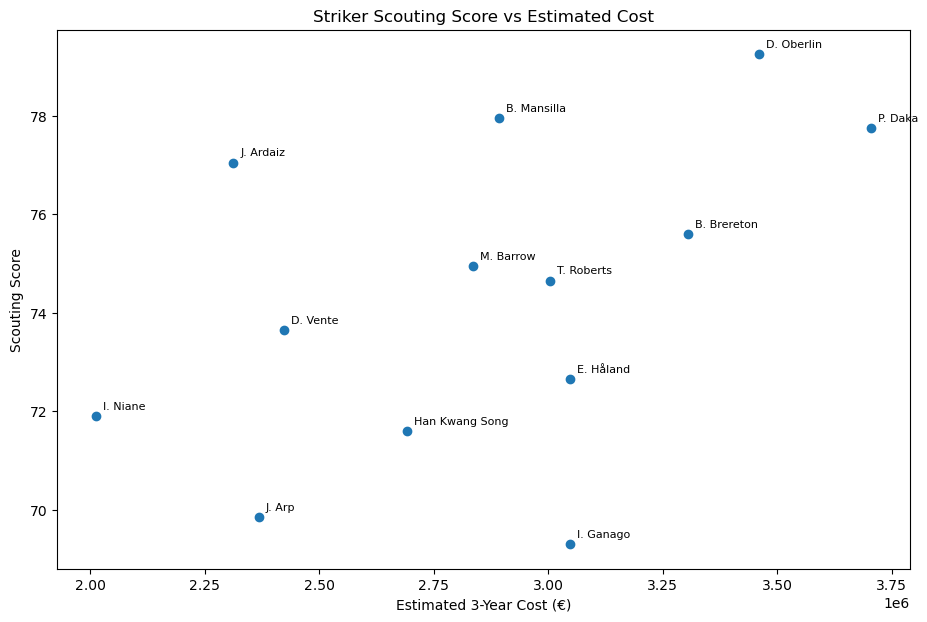

In [37]:
x = striker['Estimated_total_cost']
y = striker['scouting_score']
plt.figure(figsize=(11, 7))

plt.scatter(x,y)

plt.xlabel('Estimated 3-Year Cost (€)')
plt.ylabel('Scouting Score')
plt.title('Striker Scouting Score vs Estimated Cost')

for _, player in striker.iterrows():
    plt.annotate(
        player['name'],
        (player['Estimated_total_cost'], player['scouting_score']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

plt.show()

## Business Insights & Recommendations

### 1. Cost-Effectiveness Analysis

For a medium-sized football club with a limited budget, J. Ardaiz represents an attractive alternative to D. Oberlin.

Ardaiz has an estimated three-year cost of €2.312 million, compared with €3.460 million for Oberlin, representing potential savings of €1.148 million.

Although Oberlin has a higher scouting score (79.25 versus 77.05), Ardaiz offers a competitive tactical profile at a significantly lower estimated cost.

The comparison across all 13 shortlisted strikers also identifies B. Mansilla as a strong alternative, offering a higher scouting score than Ardaiz at a higher estimated cost. Therefore, Ardaiz should be prioritized for further evaluation based on cost-effectiveness, rather than considered the undisputed best player.

### 2. Scouting Model Sensitivity

Changing the scouting model weights from 45% speed, 35% finishing, and 20% positioning to 30% speed, 40% finishing, and 30% positioning moves J. Ardaiz from fourth to second place.

This demonstrates that player rankings depend on the tactical priorities assigned by the club.

The scouting model should therefore support recruitment decisions rather than determine them automatically.

### 3. Recruitment Recommendation

Based on the scouting scores and estimated financial costs, I recommend prioritizing J. Ardaiz for further scouting evaluation.

He combines a relatively high scouting score with one of the lowest estimated three-year costs among the shortlisted strikers.

Although some shortlisted strikers have higher potential ratings, Ardaiz offers a favorable balance between tactical suitability, development potential, and estimated three-year cost. His potential rating of 82 meets the club's minimum requirement, but it does not guarantee future development.

Before making a signing decision, the club should verify his real-world performance, tactical suitability, current availability, and actual transfer and salary requirements.

## Limitations & Conclusion

### Project Limitations

This project uses historical FIFA video game data rather than current real-world football performance data.

Player market values and wages are game-based estimates and may not reflect actual transfer fees or salary requirements.

The scouting model uses subjective attribute weights based on an assumed counter-attacking playing style. These weights have not been validated against real match performance.

Additionally, the analysis does not account for player injuries, contract situations, transfer availability, or actual match statistics.

Therefore, the results should be considered preliminary scouting recommendations rather than definitive recruitment decisions.

### Final Conclusion

This project demonstrates how data analysis can help a medium-sized football club identify promising young players while working within a limited recruitment budget.

By combining player potential, current ability, tactical suitability, and estimated financial costs, the analysis narrowed a large player database into a focused shortlist of recruitment candidates.

J. Ardaiz emerged as a promising option, offering a strong balance between scouting performance and estimated three-year cost. I recommend prioritizing him for further scouting evaluation before making a final signing decision.

Overall, the project demonstrates how data-driven scouting can support more informed and financially responsible recruitment decisions.